# AI use statement
Generative AI (Claude) was used to help debug, refine and structure the Python code in this notebook. Generative AI was not used to conceive the project or to choose its aims. All modelling decisions, analyses and interpretations are the author's own work, and the author takes full responsibility for this code.

# Agent-Based Model + Digital Twin – E. coli treated with ceftriaxone 

Every admission in the hospital is an **agent** that moves through the wards hour by hour. Each hour, an uninfected agent can pick up an *E. coli* infection. The model is built up in three stages:

| Stage | What decides a patient's chance of infection |
|---|---|
| **1 – Baseline** | The ward's device utilisation that day (Poisson Model 2). Every patient in the same ward has the same chance. |
| **2 – Crowding** | Stage 1, plus a higher chance in hours when the ward is more crowded than usual (a proxy for person-to-person transmission). |
| **3 – Agent profiles** | Each patient's **own** device status, age and sex, plus Stage 2 crowding. Patients are no longer identical. |

For each stage we replay the held-out test days **1,000 times** and compare with the real infections and the Poisson predictions. At the end we save everything the **R Shiny digital twin** (`app.R`) needs.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from pathlib import Path

# ---- Folders ----
REPO   = Path("..").resolve()                     # repository root (run this notebook from notebooks/)
DATA   = REPO / "data/synthetic_hospital"          # raw hospital CSVs (see data/README.md)
POIS   = REPO / "results/poisson"                  # files saved by the Poisson notebook
OUT    = REPO / "dashboard/data"                   # everything this notebook saves (app.R reads these)
OUT.mkdir(parents=True, exist_ok=True)

# ---- Settings ----
ORGANISM = "E coli"
DRUG     = "Ceftriaxone"
N_RUNS   = 1000       # how many times we replay the test days (per stage)
SEED     = 42         # fixes the random numbers so results are repeatable

# ---- Stage 2 setting ----
# In a crowded hour (ward above its usual busy level), a patient's chance is this many times higher.
# The synthetic data has no crowding signal (see step 6), so this is an ASSUMED value for the transmission proxy.
CROWD_FACTOR = 2.0

In [ ]:
import matplotlib.dates as mdates

# Figure styles used in the thesis
THESIS_STYLE = {"font.family": "serif", "font.serif": ["TeX Gyre Termes", "Times New Roman", "Liberation Serif"],
                "font.size": 10, "axes.titlesize": 10.5, "axes.labelsize": 10, "legend.fontsize": 8.5,
                "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e4e4e0",
                "grid.linewidth": 0.6, "axes.edgecolor": "#52514e", "axes.titleweight": "bold",
                "savefig.dpi": 300, "savefig.bbox": "tight", "lines.linewidth": 1.6, "axes.axisbelow": "line"}
BIG_FONTS = {"font.size": 15, "axes.titlesize": 16, "axes.labelsize": 15, "xtick.labelsize": 13, "ytick.labelsize": 13,
             "legend.fontsize": 13, "font.family": "DejaVu Sans", "axes.titleweight": "normal"}
WARD_COLOURS = {"ED": "#2a78d6", "ICU": "#eb6834", "Medical": "#1baf7a", "Surgical": "#6250d6"}

import sys, matplotlib
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | statsmodels {sm.__version__} | "
      f"matplotlib {matplotlib.__version__}")

## 2. Load the data

In [3]:
admissions  = pd.read_csv(DATA / "admissions.csv",       parse_dates=["admit_datetime", "discharge_datetime"])
patients    = pd.read_csv(DATA / "patients.csv")
ward_stays  = pd.read_csv(DATA / "ward_movements.csv",   parse_dates=["start_datetime", "end_datetime"])
devices     = pd.read_csv(DATA / "device_exposure.csv",  parse_dates=["start_datetime", "end_datetime"])
infections  = pd.read_csv(DATA / "infection_events.csv", parse_dates=["infection_datetime"])
medications = pd.read_csv(DATA / "medications.csv")

# From the Poisson notebook
panel      = pd.read_csv(POIS / "ward_day_panel.csv", parse_dates=["date"])                          # all ward-days
test_panel = pd.read_csv(POIS / "ecoli_ceftriaxone_panel_with_predictions.csv", parse_dates=["date"]) # test ward-days
coefs      = pd.read_csv(POIS / "ecoli_ceftriaxone_best_model_coefficients.csv").set_index("term")["coef"]
inf_ward   = pd.read_csv(POIS / "infections_attributed_to_ward.csv", parse_dates=["infection_datetime"])

# Training days = the first 70% of dates (the same split as the Poisson notebook)
all_dates   = sorted(panel["date"].unique())
train_dates = all_dates[: int(len(all_dates) * 0.7)]

print(f"{len(admissions):,} admissions (agents), {len(ward_stays):,} ward stays")
print(f"Training days: {len(train_dates)}, test days: {test_panel.date.nunique()} "
      f"({int(test_panel.new_infections.sum())} actual E. coli infections in the test period)")
print("\nPoisson Model 2 coefficients (Stage 1):\n", coefs.round(3))

20,000 admissions (agents), 33,110 ward stays
Training days: 515, test days: 112 (27 actual E. coli infections in the test period)

Poisson Model 2 coefficients (Stage 1):
 term
Intercept            -6.576
device_utilisation    1.787
Name: coef, dtype: float64


## 3. Build the agent-hours

One row = one patient, in one ward, for one hour. For each row we also record:
- **own_device** – does this patient have a device in this hour?
- **crowded** – is the ward busier than usual this hour (above its 90th percentile of patients)?

In [4]:
def to_hours(table, id_cols):
    # turn each time interval into one row per clock hour
    rows = []
    for r in table.itertuples():
        hours = pd.date_range(r.start_datetime.floor("h"), r.end_datetime.floor("h"), freq="h")
        rows.append(pd.DataFrame({**{c: getattr(r, c) for c in id_cols}, "hour_time": hours}))
    return pd.concat(rows, ignore_index=True).drop_duplicates()

hours = to_hours(ward_stays, ["admission_id", "ward"])
hours["date"] = hours["hour_time"].dt.floor("D")

# own device: hours in which the patient has any device
device_hours = to_hours(devices, ["admission_id"]).drop_duplicates()
device_hours["own_device"] = 1
hours = hours.merge(device_hours, on=["admission_id", "hour_time"], how="left")
hours["own_device"] = hours["own_device"].fillna(0).astype(int)

# crowded: more patients in the ward this hour than the ward's usual busy level (90th percentile)
patients_now = hours.groupby(["ward", "hour_time"])["admission_id"].transform("count")
threshold = hours.groupby(["ward", "hour_time"]).size().groupby("ward").quantile(0.9)
hours["crowded"] = (patients_now > hours["ward"].map(threshold)).astype(int)

# hours each patient spends in this ward on this day
hours["hours_today"] = hours.groupby(["admission_id", "ward", "date"])["hour_time"].transform("count")

# patient profile: age 65+ and sex
profile = admissions[["admission_id", "patient_id"]].merge(patients[["patient_id", "age", "sex"]], on="patient_id")
profile["age65"] = (profile["age"] >= 65).astype(int)
profile["male"] = (profile["sex"] == "Male").astype(int)
hours = hours.merge(profile[["admission_id", "age65", "male"]], on="admission_id", how="left")

# the ward's device utilisation that day (the value the Poisson model used)
hours = hours.merge(panel[["ward", "date", "device_utilisation"]], on=["ward", "date"], how="left")
hours["device_utilisation"] = hours["device_utilisation"].fillna(0)

print(f"{len(hours):,} agent-hours")
print("Crowding thresholds (patients per ward):", threshold.to_dict())
hours.head()

987,033 agent-hours
Crowding thresholds (patients per ward): {'ED': 42.0, 'ICU': 6.0, 'Medical': 14.0, 'Surgical': 13.0}


,admission_id,ward,hour_time,date,own_device,crowded,hours_today,age65,male,device_utilisation
0,1,ED,2023-09-17 07:00:00,2023-09-17,0,0,17,1,0,0.2581
1,1,ED,2023-09-17 08:00:00,2023-09-17,0,0,17,1,0,0.2581
2,1,ED,2023-09-17 09:00:00,2023-09-17,0,0,17,1,0,0.2581
3,1,ED,2023-09-17 10:00:00,2023-09-17,0,0,17,1,0,0.2581
4,1,ED,2023-09-17 11:00:00,2023-09-17,0,0,17,1,0,0.2581


## 4. One row per patient per ward per day (for fitting Stages 2 and 3)

This is exactly the Poisson model's unit (`n_at_risk`), but kept at the patient level so we can use each patient's own device, age and sex.

In [5]:
pwd = hours.groupby(["admission_id", "ward", "date"]).agg(
    own_device=("own_device", "max"),           # had a device at any time that day
    crowd_share=("crowded", "mean"),            # share of their hours that were crowded
    device_utilisation=("device_utilisation", "first"),
    age65=("age65", "first"), male=("male", "first")).reset_index()

# E. coli infections treated with ceftriaxone, matched to the patient-ward-day they happened in
drug_ids = set(medications.loc[medications.drug == DRUG, "admission_id"])
ecoli = inf_ward[(inf_ward.organism == ORGANISM) & inf_ward.admission_id.isin(drug_ids)].copy()
ecoli["date"] = ecoli["infection_datetime"].dt.floor("D")

# A few infections were detected after the patient's last ward stay ended. As in the Poisson notebook,
# they are given to the patient's last day in that ward.
last_day = pwd.groupby(["admission_id", "ward"])["date"].max().rename("last_date").reset_index()
ecoli = ecoli.merge(last_day, on=["admission_id", "ward"], how="left")
not_in_ward = ~ecoli.set_index(["admission_id", "ward", "date"]).index.isin(pwd.set_index(["admission_id", "ward", "date"]).index)
ecoli.loc[not_in_ward, "date"] = ecoli.loc[not_in_ward, "last_date"]

ecoli_count = ecoli.groupby(["admission_id", "ward", "date"]).size().rename("infected").reset_index()
pwd = pwd.merge(ecoli_count, on=["admission_id", "ward", "date"], how="left")
pwd["infected"] = pwd["infected"].fillna(0).astype(int)

train = pwd[pwd["date"].isin(train_dates)]
print(f"{len(pwd):,} patient-ward-days ({pwd.infected.sum()} infections); training: {len(train):,} ({train.infected.sum()} infections)")

72,830 patient-ward-days (164 infections); training: 51,303 (116 infections)


## 5. The infection rule (same for every stage)

Each stage gives every patient a **daily rate λ** for the ward-day they are in. It is spread evenly over the hours they are there that day:

> **p = 1 − exp(−λ × crowd_multiplier / hours_today)**

For a patient in the ward all day this is λ/24 per hour. `crowd_multiplier` is 1 in Stage 1, and used in Stages 2 and 3.

### Stage 1 – baseline (Poisson Model 2)

In [6]:
hours["lam_stage1"] = np.exp(coefs["Intercept"] + coefs["device_utilisation"] * hours["device_utilisation"])

### Stage 2 – crowding

First, does the data itself show more infections when wards are crowded? We add `crowd_share` to Model 2 and fit it on the training days.

In [7]:
m_crowd = smf.glm("infected ~ device_utilisation + crowd_share", data=train, family=sm.families.Poisson()).fit()
irr = np.exp(m_crowd.params["crowd_share"])
low, high = np.exp(m_crowd.conf_int().loc["crowd_share"])
print(f"Crowding in the data: IRR = {irr:.2f} (95% CI {low:.2f} to {high:.2f}), p = {m_crowd.pvalues['crowd_share']:.2f}")
print(f"-> no evidence of a crowding effect in the synthetic data, so Stage 2 uses the ASSUMED CROWD_FACTOR = {CROWD_FACTOR}")

# Scale so the overall infection rate stays the same as Stage 1: crowding only moves risk to crowded hours.
crowded_share_train = hours.loc[hours["date"].isin(train_dates), "crowded"].mean()
k = 1 / (1 + (CROWD_FACTOR - 1) * crowded_share_train)
hours["crowd_mult"] = k * np.where(hours["crowded"] == 1, CROWD_FACTOR, 1)
print(f"Share of patient-hours that are crowded: {crowded_share_train:.3f}; scaling k = {k:.3f}")
print(f"-> a crowded hour has {CROWD_FACTOR * k:.2f} x the Stage 1 chance, a normal hour {k:.2f} x")

Crowding in the data: IRR = 0.65 (95% CI 0.30 to 1.44), p = 0.29
-> no evidence of a crowding effect in the synthetic data, so Stage 2 uses the ASSUMED CROWD_FACTOR = 2.0
Share of patient-hours that are crowded: 0.115; scaling k = 0.897
-> a crowded hour has 1.79 x the Stage 1 chance, a normal hour 0.90 x


          mean   50%   max
ward                      
ED        34.0  34.0  55.0
ICU        3.2   3.0  10.0
Medical    9.6   9.0  25.0
Surgical   9.3   9.0  26.0



Share of agent-hours crowded: {'ED': 0.11, 'ICU': 0.087, 'Medical': 0.115, 'Surgical': 0.162}
Mean crowding multiplier over the test period: 1.001


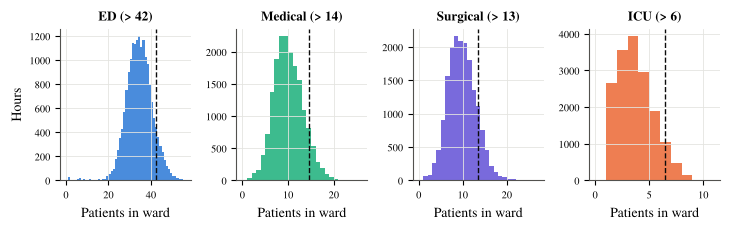

In [8]:
# Hourly occupancy, crowding thresholds and share of crowded agent-hours by ward (Figure B.4)
occupancy = hours.groupby(["ward", "hour_time"]).size().rename("patients").reset_index()
print(occupancy.groupby("ward")["patients"].describe()[["mean", "50%", "max"]].round(1).to_string())
print("\nShare of agent-hours crowded:", hours.groupby("ward")["crowded"].mean().round(3).to_dict())
print(f"Mean crowding multiplier over the test period: {hours.loc[hours['date'].isin(test_panel['date']), 'crowd_mult'].mean():.3f}")

with plt.rc_context(THESIS_STYLE):
    fig, axes = plt.subplots(1, 4, figsize=(7.4, 2.4))
    for ax, ward in zip(axes, ["ED", "Medical", "Surgical", "ICU"]):
        values = occupancy.loc[occupancy["ward"] == ward, "patients"]
        ax.hist(values, bins=range(0, int(values.max()) + 2), color=WARD_COLOURS[ward], alpha=0.85)
        ax.axvline(threshold[ward] + 0.5, color="#0b0b0b", ls="--", lw=1)
        ax.set_title(f"{ward} (> {int(threshold[ward])})", fontsize=9.5)
        ax.set_xlabel("Patients in ward"); ax.tick_params(labelsize=7.5)
    axes[0].set_ylabel("Hours")
    fig.tight_layout(); fig.savefig(OUT / "crowding_thresholds.png"); plt.show()

### Stage 3 – agent profiles

A Poisson model at the **patient** level, fitted on the training days: each patient's daily rate depends on their own device, age (65+) and sex.

In [9]:
m_agent = smf.glm("infected ~ own_device + age65 + male", data=train, family=sm.families.Poisson()).fit()
ci = np.exp(m_agent.conf_int())
stage3_table = pd.DataFrame({"coef": m_agent.params, "IRR": np.exp(m_agent.params),
                             "IRR_2.5%": ci[0], "IRR_97.5%": ci[1], "p_value": m_agent.pvalues}).round(3)
print(stage3_table)

b = m_agent.params
hours["lam_stage3"] = np.exp(b["Intercept"] + b["own_device"] * hours["own_device"]
                             + b["age65"] * hours["age65"] + b["male"] * hours["male"])

             coef    IRR  IRR_2.5%  IRR_97.5%  p_value
Intercept  -6.357  0.002     0.001      0.002    0.000
own_device  0.307  1.359     0.914      2.020    0.130
age65      -0.086  0.918     0.624      1.349    0.663
male        0.393  1.481     1.024      2.143    0.037


## 6. Check: does Stage 1 have the same daily pattern as the Poisson model?

We add up every patient's risk for each test ward-day (Stage 1's **expected** infections) and compare it with the Poisson prediction.

In [10]:
test_panel = test_panel.reset_index(drop=True)
test_panel["row"] = test_panel.index
test_hours = hours.merge(test_panel[["ward", "date", "row"]], on=["ward", "date"])   # test days only
test_hours = test_hours.sort_values("hour_time").reset_index(drop=True)

def hourly_chance(lam, crowd_mult=1):
    return 1 - np.exp(-lam * crowd_mult / test_hours["hours_today"])

p_stage = {
    "Stage 1": hourly_chance(test_hours["lam_stage1"]),
    "Stage 2": hourly_chance(test_hours["lam_stage1"], test_hours["crowd_mult"]),
    "Stage 3": hourly_chance(test_hours["lam_stage3"], test_hours["crowd_mult"]),
}

expected = (-np.log(1 - p_stage["Stage 1"])).groupby(test_hours["row"]).sum()
test_panel["stage1_expected"] = expected.reindex(test_panel["row"]).fillna(0).to_numpy()
print(f"Correlation Stage 1 expected vs Poisson (ward-days): {np.corrcoef(test_panel.stage1_expected, test_panel.predicted)[0, 1]:.4f}")
print(f"Largest difference on any ward-day: {(test_panel.stage1_expected - test_panel.predicted).abs().max():.6f}")

Correlation Stage 1 expected vs Poisson (ward-days): 1.0000
Largest difference on any ward-day: 0.000000


## 7. Run the ABM – replay the test days 1,000 times, for each stage

In each run, every agent-hour gets a random number between 0 and 1. The patient is infected in the **first hour** where that number is below p; after that they are no longer at risk (at most one infection per admission).

In [11]:
def run_abm(p, n_runs=N_RUNS, seed=SEED):
    rng = np.random.default_rng(seed)
    sim = np.zeros((n_runs, len(test_panel)))          # sim[run, ward-day] = simulated infections
    hour_of_day = np.zeros(24)
    for run in range(n_runs):
        hit = rng.random(len(test_hours)) < p.to_numpy()                     # which agent-hours "roll" an infection
        first = test_hours[hit].drop_duplicates("admission_id")             # each patient's first infection only
        sim[run] = np.bincount(first["row"], minlength=len(test_panel))     # count per ward-day
        hour_of_day += np.bincount(first["hour_time"].dt.hour, minlength=24)
    return sim, hour_of_day / n_runs

results = {stage: run_abm(p) for stage, p in p_stage.items()}
print("Done:", list(results))

Done: ['Stage 1', 'Stage 2', 'Stage 3']


## 8. What does the distribution of the results look like? (Stage 1)

If the results are **skewed**, mean ± 1.96 SD can be misleading, so **quantiles** (2.5% and 97.5%) are safer.

Hospital total (1,000 runs): mean 23.0, median 23, skewness 0.22
  95% by quantiles:      14 to 32
  95% by mean ± 1.96 SD: 13.8 to 32.2
One ED day: share of runs with 0 / 1 / 2+ infections = 0.85 / 0.14 / 0.01, skewness 2.56
Share of runs with at least the observed 27 infections: 21.3%


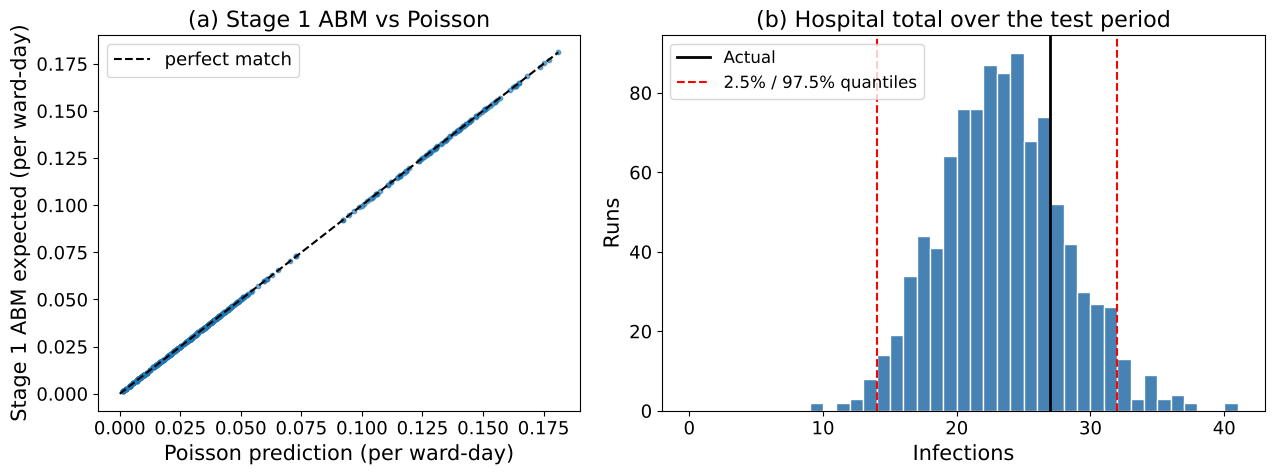

In [12]:
sim1 = results["Stage 1"][0]
hospital_total = sim1.sum(axis=1)
print(f"Hospital total (1,000 runs): mean {hospital_total.mean():.1f}, median {np.median(hospital_total):.0f}, "
      f"skewness {pd.Series(hospital_total).skew():.2f}")
print(f"  95% by quantiles:      {np.quantile(hospital_total, 0.025):.0f} to {np.quantile(hospital_total, 0.975):.0f}")
print(f"  95% by mean ± 1.96 SD: {hospital_total.mean() - 1.96 * hospital_total.std():.1f} to {hospital_total.mean() + 1.96 * hospital_total.std():.1f}")

one_day = test_panel[test_panel.ward == "ED"]["predicted"].idxmax()
day_counts = sim1[:, one_day]
print(f"One ED day: share of runs with 0 / 1 / 2+ infections = {(day_counts == 0).mean():.2f} / "
      f"{(day_counts == 1).mean():.2f} / {(day_counts >= 2).mean():.2f}, skewness {pd.Series(day_counts).skew():.2f}")
print(f"Share of runs with at least the observed {int(test_panel.new_infections.sum())} infections: "
      f"{(hospital_total >= test_panel.new_infections.sum()).mean():.1%}")

# Figure 4.7: (a) Stage 1 expected vs Poisson for each test ward-day, (b) hospital total over 1,000 runs
with plt.rc_context(BIG_FONTS):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.25]})
    ax = axes[0]
    ax.scatter(test_panel["predicted"], test_panel["stage1_expected"], s=10, alpha=0.6)
    ax.plot([0, test_panel.predicted.max()], [0, test_panel.predicted.max()], "k--", label="perfect match")
    ax.set_xlabel("Poisson prediction (per ward-day)"); ax.set_ylabel("Stage 1 ABM expected (per ward-day)")
    ax.set_title("(a) Stage 1 ABM vs Poisson"); ax.legend()
    ax = axes[1]
    ax.hist(hospital_total, bins=range(int(hospital_total.max()) + 2), color="steelblue", edgecolor="white")
    ax.axvline(test_panel.new_infections.sum(), color="black", lw=2, label="Actual")
    ax.axvline(np.quantile(hospital_total, 0.025), color="red", ls="--", label="2.5% / 97.5% quantiles")
    ax.axvline(np.quantile(hospital_total, 0.975), color="red", ls="--")
    ax.set_title("(b) Hospital total over the test period"); ax.set_xlabel("Infections"); ax.set_ylabel("Runs")
    ax.legend(fontsize=12)
    plt.tight_layout(); plt.savefig(OUT / "abm_verification_validation.png", dpi=150); plt.show()

**How to read this:** the hospital total is close to symmetric, but a single day is very skewed (mostly 0). So we always report the **2.5% and 97.5% quantiles** as the 95% range: the median for totals, and the mean (expected number) for daily values.

## 9. Compare the three stages (test days only)

For each stage and ward: median of the 1,000 simulated totals with the 2.5% and 97.5% quantiles, whether the actual total is inside that range, and the share of ward-days whose actual count is inside its own 95% range. The risk ratio compares the average total risk of patients who were actually infected with that of patients who were not (above 1 = the model gives more risk to the patients who became infected).

In [13]:
wards = sorted(test_panel["ward"].unique())
infected_ids = set(ecoli.loc[ecoli["date"].isin(test_panel["date"]), "admission_id"])
is_infected = test_hours["admission_id"].isin(infected_ids)

rows = []
for stage, (sim, _) in results.items():
    for ward in wards + ["Hospital"]:
        keep = np.ones(len(test_panel), bool) if ward == "Hospital" else (test_panel["ward"] == ward).to_numpy()
        totals = sim[:, keep].sum(axis=1)
        rows.append({"stage": stage, "ward": ward,
                     "actual": test_panel.loc[keep, "new_infections"].sum(),
                     "poisson": round(test_panel.loc[keep, "predicted"].sum(), 1),
                     "abm_median": np.median(totals),
                     "abm_95_low": np.quantile(totals, 0.025),
                     "abm_95_high": np.quantile(totals, 0.975)})
summary = pd.DataFrame(rows)
summary["actual_inside_95"] = summary["actual"].between(summary["abm_95_low"], summary["abm_95_high"])

# One line per stage: overall accuracy and how well risk separates infected from non-infected patients
overview = []
for stage, (sim, _) in results.items():
    mean_per_day = sim.mean(axis=0)
    risk = -np.log(1 - p_stage[stage])                                   # each agent-hour's risk
    patient_risk = risk.groupby(test_hours["admission_id"]).sum()        # total risk per patient
    overview.append({"stage": stage,
                     "hospital_median": np.median(sim.sum(axis=1)),
                     "ward_day_MAE": (mean_per_day - test_panel["new_infections"]).abs().mean(),
                     "ward_days_inside_95": np.mean((test_panel["new_infections"] >= np.quantile(sim, 0.025, axis=0)) &
                                                    (test_panel["new_infections"] <= np.quantile(sim, 0.975, axis=0))),
                     "risk_ratio_infected_vs_not": patient_risk[patient_risk.index.isin(infected_ids)].mean()
                                                   / patient_risk[~patient_risk.index.isin(infected_ids)].mean()})
overview = pd.DataFrame(overview).round(3)

summary.to_csv(OUT / "abm_validation_summary.csv", index=False)
overview.to_csv(OUT / "abm_stage_overview.csv", index=False)
print(overview.to_string(index=False))
summary.pivot(index="ward", columns="stage", values="abm_median").assign(
    actual=summary.groupby("ward")["actual"].first(), poisson=summary.groupby("ward")["poisson"].first())

  stage  hospital_median  ward_day_MAE  ward_days_inside_95  risk_ratio_infected_vs_not
Stage 1             23.0         0.101                0.998                       1.097
Stage 2             23.0         0.101                0.995                       1.077
Stage 3             23.0         0.101                0.995                       1.047


stage,Stage 1,Stage 2,Stage 3,actual,poisson
ward,,,,,
ED,14.0,14.0,13.0,20,14.1
Hospital,23.0,23.0,23.0,27,23.0
ICU,1.0,1.0,1.0,0,1.2
Medical,4.0,4.0,4.0,3,3.8
Surgical,4.0,4.0,4.0,4,3.9


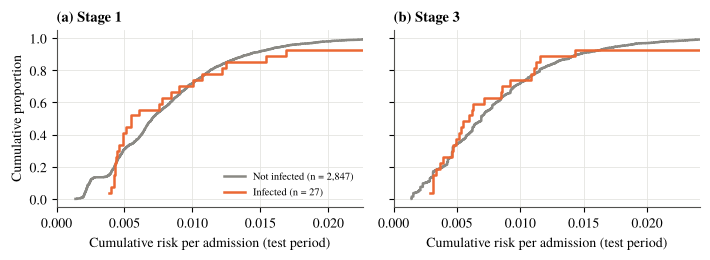

In [14]:
# Figure B.7: cumulative risk per admission over the test period, infected vs not infected
with plt.rc_context(THESIS_STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.7), sharey=True)
    for ax, stage, letter in zip(axes, ["Stage 1", "Stage 3"], ["a", "b"]):
        risk = (-np.log(1 - p_stage[stage])).groupby(test_hours["admission_id"]).sum()
        infected = risk.index.isin(infected_ids)
        for values, colour, label in [(risk[~infected], "#8a8984", f"Not infected (n = {(~infected).sum():,})"),
                                      (risk[infected], "#eb6834", f"Infected (n = {infected.sum()})")]:
            xs = np.sort(values.values)
            ax.step(xs, np.arange(1, len(xs) + 1) / len(xs), color=colour, lw=1.8, label=label, where="post")
        ax.set_xlim(0, np.quantile(risk, 0.99))
        ax.set_title(f"({letter}) {stage}", loc="left")
        ax.set_xlabel("Cumulative risk per admission (test period)")
    axes[0].set_ylabel("Cumulative proportion"); axes[0].legend(frameon=False, loc="lower right", fontsize=7.5)
    fig.tight_layout(); fig.savefig(OUT / "risk_infected_vs_not.png"); plt.show()

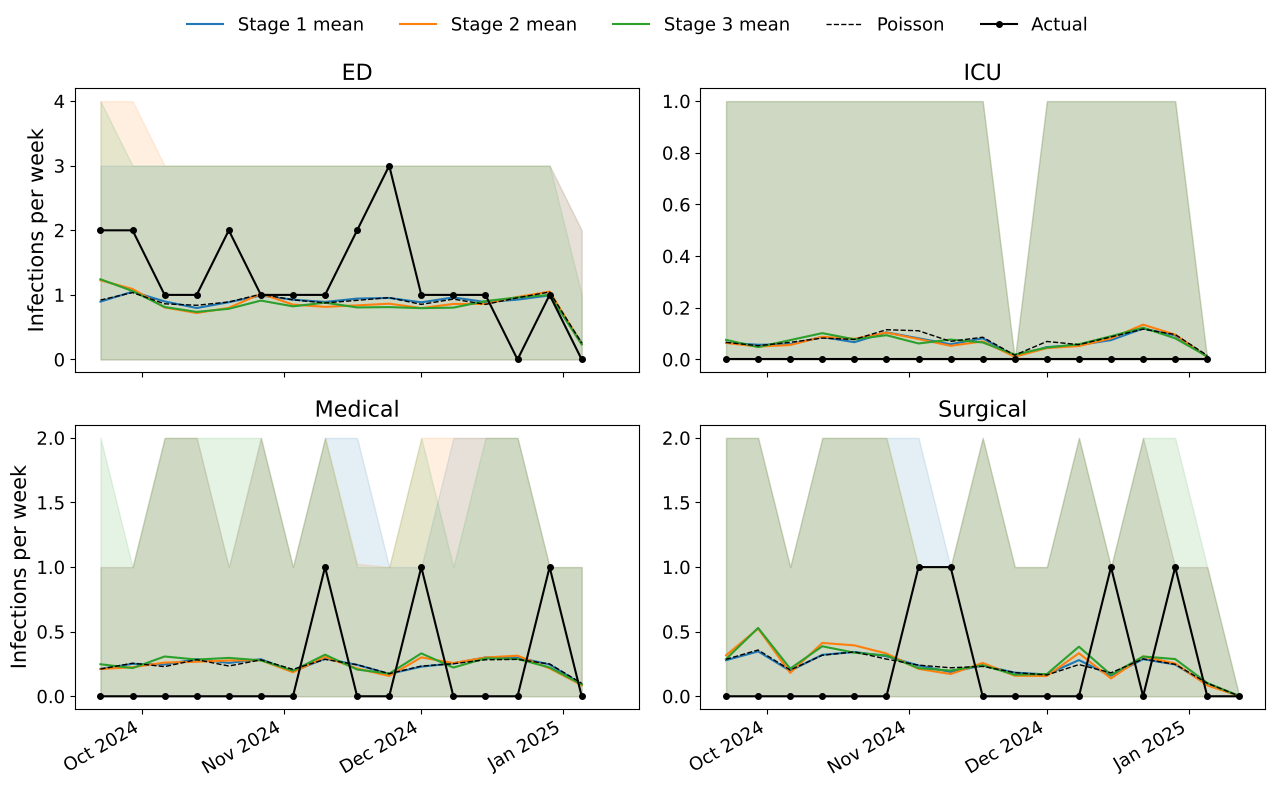

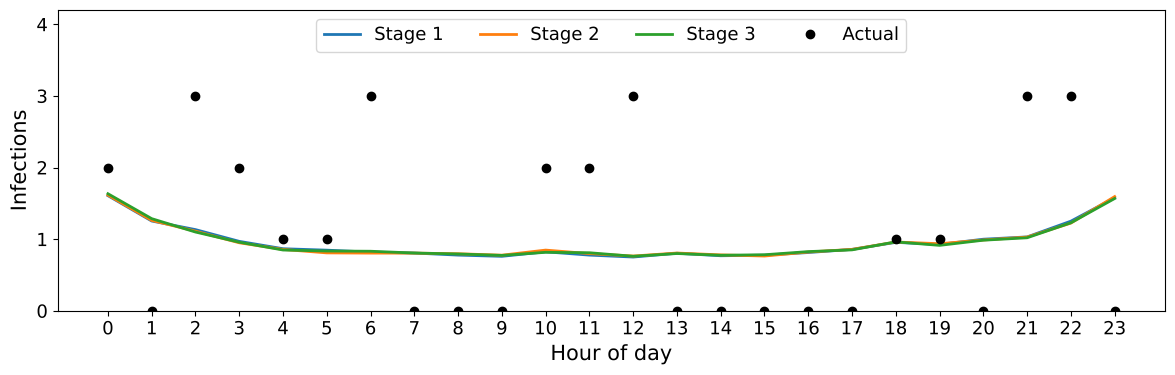

Stage 1 mean infections at 23:00-00:00: 1.59; at 11:00-13:00: 0.78


In [15]:
# ---- Weekly infections per ward, all three stages (Figure B.5) ----
def weekly(ward, values):
    # add up one ward's ward-days into weeks (values: one row per ward-day)
    keep = (test_panel["ward"] == ward).to_numpy()
    return pd.DataFrame(values[keep], index=test_panel.loc[keep, "date"]).resample("W").sum()

colours = {"Stage 1": "tab:blue", "Stage 2": "tab:orange", "Stage 3": "tab:green"}
with plt.rc_context(BIG_FONTS):
    fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
    for ax, ward in zip(axes.flat, wards):
        a = weekly(ward, test_panel[["new_infections", "predicted"]].to_numpy())
        for stage, (sim, _) in results.items():
            w = weekly(ward, sim.T)
            ax.fill_between(w.index, w.quantile(0.025, axis=1), w.quantile(0.975, axis=1), color=colours[stage], alpha=0.12)
            ax.plot(w.index, w.mean(axis=1), color=colours[stage], label=f"{stage} mean")
        ax.plot(a.index, a[1], "k--", lw=1, label="Poisson")
        ax.plot(a.index, a[0], "o-", color="black", ms=4, label="Actual")
        ax.set_title(ward)
        ax.xaxis.set_major_locator(mdates.MonthLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, ncol=5, loc="upper center", frameon=False, bbox_to_anchor=(0.5, 1.0))
    axes[0, 0].set_ylabel("Infections per week"); axes[1, 0].set_ylabel("Infections per week")
    fig.autofmt_xdate(); plt.tight_layout(rect=(0, 0, 1, 0.95))
    plt.savefig(OUT / "abm_validation_by_ward.png", dpi=150); plt.show()

# ---- When in the day do infections happen? (Figure 4.8) ----
actual_hours = ecoli[ecoli["infection_datetime"].dt.floor("D").isin(test_panel["date"])]["infection_datetime"].dt.hour
with plt.rc_context(BIG_FONTS):
    fig, ax = plt.subplots(figsize=(12, 4))
    for stage, (_, by_hour) in results.items():
        ax.plot(range(24), by_hour, color=colours[stage], label=stage, lw=2)
    ax.plot(range(24), np.bincount(actual_hours, minlength=24), "o", color="black", label="Actual")
    ax.set_xticks(range(24)); ax.set_xlabel("Hour of day"); ax.set_ylabel("Infections")
    ax.legend(ncol=4, loc="upper center"); ax.set_ylim(0, 4.2)
    plt.tight_layout(); plt.savefig(OUT / "abm_validation_hour_of_day.png", dpi=150); plt.show()

by_hour_s1 = results["Stage 1"][1]
print(f"Stage 1 mean infections at 23:00-00:00: {by_hour_s1[[23, 0]].mean():.2f}; at 11:00-13:00: {by_hour_s1[[11, 12, 13]].mean():.2f}")

**How to read the stage comparison**
- **Totals:** Stage 2 keeps the same overall rate as Stage 1 (it only moves risk into crowded hours), so totals are very similar. Stage 3 is fitted at the patient level and gives almost the same totals.
- **Risk ratio:** infected patients had only slightly higher risk than uninfected patients in every stage (ratio close to 1), so individual risks are only weakly informative in the synthetic data.
- The synthetic data has no crowding signal, so Stage 2 shows **how** crowding would change the picture, not evidence that it does.
- **Hour of day:** simulated infections are higher around midnight. This is a side effect of spreading each patient's daily risk over the hours they are in the ward that day: patients who are there for only a few hours either side of midnight get a bigger share per hour. It comes from the Poisson model counting any part of a day as one patient-day.

## 10. Save everything the digital twin (`app.R`) needs

In [16]:
# 1. Model settings for each stage
coefs.rename("coef").to_csv(OUT / "coefficients.csv")                                  # Stage 1
stage3_table.to_csv(OUT / "stage3_coefficients.csv")                                    # Stage 3
pd.Series({"crowd_factor": CROWD_FACTOR, "k": k, "data_irr": irr, "crowded_share": crowded_share_train}).rename("value").to_csv(OUT / "stage2_crowding.csv")

# 2. Per ward: chance a patient has a device, and the crowding threshold
ward_params = pd.DataFrame({"device_prob": panel.groupby("ward")["device_utilisation"].mean(),
                            "crowd_threshold": threshold}).round(4)
ward_params.to_csv(OUT / "ward_params.csv")

# 3. Where patients go next (rows = current ward, columns = next ward)
ws = ward_stays.sort_values(["admission_id", "start_datetime"]).copy()
ws["next_ward"] = ws.groupby("admission_id")["ward"].shift(-1).fillna("DISCHARGE")
pd.crosstab(ws["ward"], ws["next_ward"], normalize="index").round(4).to_csv(OUT / "transitions.csv")

# 4. How long patients stay in each ward, in hours
ws["hours"] = ((ws["end_datetime"] - ws["start_datetime"]).dt.total_seconds() / 3600).round(2)
ws[["ward", "hours"]].to_csv(OUT / "stay_hours.csv", index=False)

# 5. Average arrivals per hour by weekday, and the share of arrivals aged 65+ and male (for new agents)
admissions["weekday"] = admissions["admit_datetime"].dt.day_name()
admissions["hour"] = admissions["admit_datetime"].dt.hour
n_weeks = admissions["admit_datetime"].dt.floor("D").nunique() / 7
(admissions.groupby(["weekday", "hour"]).size() / n_weeks).rename("mean_arrivals").round(3).to_csv(OUT / "arrivals_by_hour.csv")
pd.Series({"age65": profile["age65"].mean(), "male": profile["male"].mean()}).rename("share").round(4).to_csv(OUT / "arrival_profile.csv")

# 6. Daily E. coli infections over the whole history (grey and red dots on the dashboard)
last_admit = admissions.admit_datetime.max().floor("D")
days = pd.date_range(admissions.admit_datetime.min().floor("D"), last_admit, freq="D")
daily = ecoli.groupby(ecoli["infection_datetime"].dt.floor("D")).size().reindex(days, fill_value=0)
daily = daily.rename("infections").rename_axis("date").reset_index()
daily["weekday"] = daily["date"].dt.day_name()
daily.to_csv(OUT / "daily_infections_history.csv", index=False)

# 7. Starting hospital: who is in which ward at one moment, hours left there, age 65+ and sex
SNAPSHOT = last_admit - pd.Timedelta(days=14) + pd.Timedelta(hours=12)
now_in = ward_stays[(ward_stays.start_datetime <= SNAPSHOT) & (ward_stays.end_datetime > SNAPSHOT)].copy()
now_in["hours_left"] = ((now_in["end_datetime"] - SNAPSHOT).dt.total_seconds() / 3600).round(2)
now_in = now_in.merge(profile[["admission_id", "age65", "male"]], on="admission_id")
now_in[["admission_id", "ward", "hours_left", "age65", "male"]].to_csv(OUT / "start_state.csv", index=False)

print("Saved to", OUT)
print(f"Starting hospital at {SNAPSHOT}: {len(now_in)} patients ->", now_in.ward.value_counts().to_dict())

Saved to dashboard/data
Starting hospital at 2024-12-16 12:00:00: 57 patients -> {'ED': 39, 'Surgical': 8, 'ICU': 7, 'Medical': 3}


## 11. Evaluation of the live signal (Table 4.8, Figure 4.10)

The twin multiplies expected ED arrivals by the live ratio (patients waiting now ÷ usual for this hour, limited to 0.5-2) for the next six hours. Here every pair of distinct readings on the same day, up to six hours apart, is used to forecast the later reading in three ways: the website's hourly average alone, the twin's live rule, and the earlier reading itself (persistence).

             website_updated  patients_waiting  usual  ratio  ratio_applied  median_wait_min
25 September 2026 7:15:23 PM                 7    4.8   1.46           1.46               29
25 September 2026 7:30:26 PM                 9    4.8   1.88           1.88               27
25 September 2026 7:45:22 PM                 7    4.8   1.46           1.46               26
25 September 2026 8:00:25 PM                 7    4.5   1.56           1.56               44
25 September 2026 8:15:24 PM                 7    4.5   1.56           1.56               38
25 September 2026 8:30:29 PM                 5    4.5   1.11           1.11               44
25 September 2026 8:45:36 PM                 3    4.5   0.67           0.67               36
  7 October 2026 11:30:12 AM                16    5.3   3.02           2.00                8
  7 October 2026 11:45:11 AM                15    5.3   2.83           2.00               10

12 distinct readings, 25 pairs
             err_base  err_live_rule  

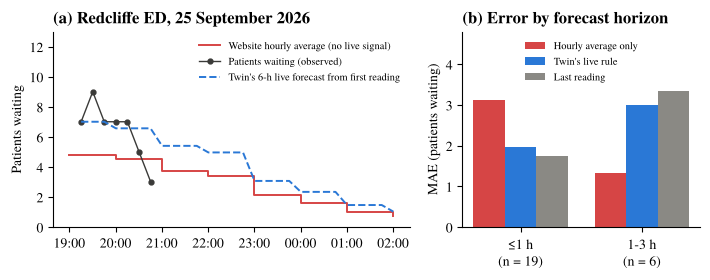

In [17]:
live = pd.read_csv(OUT / "live_log.csv")
busy = pd.read_csv(OUT / "busyness_log.csv")
live["updated"] = pd.to_datetime(live["website_updated"], format="%d %B %Y %I:%M:%S %p")
live = live.drop_duplicates("website_updated").sort_values("updated").reset_index(drop=True)   # distinct website updates
live["date"] = live["updated"].dt.strftime("%Y-%m-%d")
usual = busy.set_index(["date", "hour"])["avg_waiting"]
live["usual"] = [usual.get((d, h), np.nan) for d, h in zip(live["date"], live["updated"].dt.hour)]
live["ratio"] = live["patients_waiting"] / live["usual"]
live["ratio_applied"] = live["ratio"].clip(0.5, 2)

# Table 4.8: readings captured during the dashboard sessions (25 September and 7 October 2026)
sessions = live[live["date"].isin(["2026-09-25", "2026-10-07"])]
print(sessions[["website_updated", "patients_waiting", "usual", "ratio", "ratio_applied", "median_wait_min"]].round(2).to_string(index=False))

pairs = []
for i in range(len(live)):
    for j in range(i + 1, len(live)):
        horizon = (live.updated[j] - live.updated[i]).total_seconds() / 3600
        if live.date[i] == live.date[j] and 0 < horizon <= 6:
            pairs.append(dict(horizon=horizon, actual=live.patients_waiting[j], base=live.usual[j],
                              live_rule=live.usual[j] * live.ratio_applied[i], persist=live.patients_waiting[i]))
pairs = pd.DataFrame(pairs)
for c in ["base", "live_rule", "persist"]:
    pairs[f"err_{c}"] = (pairs[c] - pairs["actual"]).abs()
pairs["horizon_bin"] = pd.cut(pairs["horizon"], [0, 1, 3, 6], labels=["≤1 h", "1-3 h", "3-6 h"])
mae = pairs.groupby("horizon_bin", observed=True)[["err_base", "err_live_rule", "err_persist"]].mean().round(2)
mae["pairs"] = pairs.groupby("horizon_bin", observed=True).size()
print(f"\n{len(live)} distinct readings, {len(pairs)} pairs")
print(mae.to_string())
print("Overall MAE:", pairs[["err_base", "err_live_rule", "err_persist"]].mean().round(2).to_dict())
print(f"Readings above the usual level: {(live['ratio'] > 1).sum()} of {len(live)}, "
      f"by {(live['patients_waiting'] - live['usual']).mean():.1f} patients on average")

# Figure 4.10: (a) the day with most readings, (b) MAE by horizon
day = live["date"].value_counts().idxmax()
d = live[live["date"] == day]
first = d.index[0]
LIVE_STYLE = {"font.family": "serif", "font.serif": THESIS_STYLE["font.serif"], "font.size": 10,
              "axes.spines.top": False, "axes.spines.right": False, "savefig.dpi": 300, "savefig.bbox": "tight"}
with plt.rc_context(LIVE_STYLE):
    fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.9), gridspec_kw={"width_ratios": [1.5, 1]})
    hrs = pd.date_range(d.updated[first].floor("h"), d.updated[first].floor("h") + pd.Timedelta(hours=7), freq="h")
    ax[0].step(hrs, [usual.get((day, t.hour), np.nan) for t in hrs], where="post", color="#d64545", lw=1.4,
               label="Website hourly average (no live signal)")
    ax[0].plot(d.updated, d.patients_waiting, "o-", color="#3a3a38", ms=3.5, lw=1, label="Patients waiting (observed)")
    fh = pd.date_range(d.updated[first], periods=7 * 4, freq="15min")
    ax[0].plot(fh, [usual.get((day, t.hour), np.nan) * d.ratio_applied[first] for t in fh], color="#2a78d6", ls="--", lw=1.4,
               label="Twin's 6-h live forecast from first reading")
    ax[0].set_ylabel("Patients waiting"); ax[0].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax[0].set_title(f"(a) Redcliffe ED, {pd.Timestamp(day):%d %B %Y}", loc="left", fontweight="bold")
    ax[0].legend(frameon=False, fontsize=7.5, loc="upper right"); ax[0].set_ylim(0, 13)
    x = np.arange(len(mae)); w = 0.26
    for k, (col, label, colour) in enumerate([("err_base", "Hourly average only", "#d64545"),
                                              ("err_live_rule", "Twin's live rule", "#2a78d6"),
                                              ("err_persist", "Last reading", "#8a8984")]):
        ax[1].bar(x + (k - 1) * w, mae[col], width=w, color=colour, label=label)
    ax[1].set_xticks(x); ax[1].set_xticklabels([f"{a}\n(n = {n})" for a, n in zip(mae.index, mae["pairs"])])
    ax[1].set_ylabel("MAE (patients waiting)"); ax[1].set_title("(b) Error by forecast horizon", loc="left", fontweight="bold")
    ax[1].legend(frameon=False, fontsize=7.5, loc="upper center"); ax[1].set_ylim(0, 4.8)
    fig.tight_layout(); fig.savefig(OUT / "live_signal_evaluation.png"); plt.show()